# Case 01: The lift we could not trust

**Decision under review.** A redesigned checkout widget is on a 50/50 user-randomised test. Enrolment runs for 21 days; this notebook is the interim look, which reads the users enrolled in the first 14 days once their outcomes are complete. The product lead will ship if the lower bound of the 95% interval on the relative intent-to-treat lift in the 7-day completed-order rate is above +1.0%, the payment-step and latency guardrails pass their pre-declared margins, the refund guardrail shows no breach and no decision blocker is open. The team dashboard, read on day 14, shows a lift large enough to clear that bar (step 6).

**What this notebook does.** It follows the investigation a competent reviewer runs *before* reading the effect estimate: assignment counts, exposure counts, exposure by segment, invariants on the assigned and on the analysed population, outcome-event completeness, and only then the estimate. Every estimate and test comes from a package function that states its estimand, assumptions and warnings, except the latency bootstrap and the guardrail verdict, which are defined in this notebook and marked as such.

**Data.** All data is simulated (`abf simulate case01`, seed in `config.yaml`, manifest in `data/manifests/case01.json`). The incident is a plausible telemetry mechanism and is never described as a real outage. The notebook never reads the `truth` table, which is written for audit only. The seed was selected by a stated rule to show this pattern, and a random seed shows it in about one run in five (README, operating characteristics); the simulation generates only the cohorts this interim look reads.

| Unit | Definition |
|---|---|
| Randomisation | user, by hash of user id at first eligibility |
| Eligibility | user requesting the checkout page in the window |
| Exposure | user for whom the checkout widget emitted a render event |
| Outcome | any completed order within 7 days of first eligibility |
| Analysis | user |

**Primary estimand.** Intent-to-treat difference in expected 7-day order rate among eligible users, E[Y(1) − Y(0)], reported absolute and as a relative lift over control.
**Secondary estimand (the dashboard's).** The same difference among users whose widget *renders*; the dashboard's logged-exposed population targets it only when the render event is logged the same way in both arms. About 15% of eligible users never have the widget rendered, in both arms alike; they cannot be affected by it, so the ITT effect is the rendered-user effect diluted by them. A triggered analysis is legitimate, and more sensitive, when the trigger is independent of arm (the operating-characteristic scenarios in the README measure this); it stops being one when the trigger event is logged differentially.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

from abforensics import (
    difference_in_proportions,
    event_arrival_lag,
    exposure_rate_by_segment,
    invariant_check,
    srm_check,
)
from abforensics.reporting import BLUE_CMAP, PALETTE, apply_style
from abforensics.simulation.checkout_incident import version_below

apply_style()
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
CASE = ROOT / "case_studies" / "01_lift_we_could_not_trust"
DATA = ROOT / "data" / "generated" / "case01"
FIG = CASE / "figures"
FIG.mkdir(exist_ok=True)
config = yaml.safe_load((CASE / "config.yaml").read_text())

if not DATA.exists():
    from abforensics.cli import main as abf_main
    abf_main(["simulate", "case01"])

tables = {name: pd.read_parquet(DATA / f"{name}.parquet")
          for name in ["users", "assignments", "exposures", "checkout_attempts", "orders", "telemetry_health"]}
users, assignments, exposures = tables["users"], tables["assignments"], tables["exposures"]
attempts, orders, telemetry = tables["checkout_attempts"], tables["orders"], tables["telemetry_health"]
pd.DataFrame({"rows": {k: len(v) for k, v in tables.items()}})

,rows
users,280000
assignments,280000
exposures,233889
checkout_attempts,364031
orders,8990
telemetry_health,182


## Pre-registered decision rule and analysis clock

The interim look reads the users enrolled on days 1 to 14. The outcome window is 7 days per user and orders arrive through a batch pipeline with up to 36 hours of delay, so those cohorts' outcomes are complete only at **day 14 + 7 days + 36 hours**, while enrolment continues to day 21. The dashboard the product lead is looking at was rendered on day 14. Two different analysis clocks, then: `dashboard_time` (what they saw) and `analysis_time` (when the interim cohorts' data is complete).

In [2]:
t0 = assignments["assigned_at"].min().floor("D")
window = pd.Timedelta(days=config["outcome_window_days"])
max_delay = pd.Timedelta(hours=config["order_pipeline"]["arrival_delay_hours"]["max"])
dashboard_time = t0 + pd.Timedelta(days=config["days"])
analysis_time = dashboard_time + window + max_delay
threshold = config["decision_rule"]["ship_if_lower_bound_above_relative"]
alloc = config["allocation"]
print(f"experiment start {t0:%Y-%m-%d}, dashboard rendered {dashboard_time:%Y-%m-%d}, "
      f"data complete {analysis_time:%Y-%m-%d %H:%M}")
print(f"ship rule: lower 95% bound on relative ITT lift > {threshold:+.1%}, must-pass guardrails pass, "
      "no guardrail breaches, no open blocker")

experiment start 2026-03-02, dashboard rendered 2026-03-16, data complete 2026-03-24 12:00
ship rule: lower 95% bound on relative ITT lift > +1.0%, must-pass guardrails pass, no guardrail breaches, no open blocker


## Step 1: assignment-level sample ratio check

Counts of *assigned* users per arm against the configured 50/50 allocation. This is the check every platform runs. Threshold 0.001, as platforms use, because this test fires on every experiment every day.

In [3]:
assigned_counts = assignments["arm"].value_counts().to_dict()
srm_assignment = srm_check(assigned_counts, alloc, level="assignment")
print(srm_assignment.summary())
for w in srm_assignment.warnings:
    print("warning:", w)

SRM check at assignment level: compatible with planned allocation. control=140,164 (expected 140,000), treatment=139,836 (expected 140,000); chi2=0.38, df=1, p=0.535, alpha=0.001.


## Step 2: exposure-level sample ratio check

The dashboard analyses users who *rendered the widget*, because the widget only exists for users who reach checkout. So the population it compares is the exposed one, and the check has to be run there too.

In [4]:
exposed_users = assignments[assignments["user_id"].isin(exposures["user_id"])]
exposed_counts = exposed_users["arm"].value_counts().to_dict()
srm_exposure = srm_check(exposed_counts, alloc, level="exposure")
print(srm_exposure.summary())
missing_by_arm = {arm: assigned_counts[arm] - exposed_counts[arm] for arm in assigned_counts}
print("assigned users with no exposure event:", missing_by_arm)

SRM check at exposure level: MISMATCH with planned allocation. control=119,182 (expected 116,944), treatment=114,707 (expected 116,944); chi2=85.62, df=1, p=2.18e-20, alpha=0.001.
assigned users with no exposure event: {'control': 20982, 'treatment': 25129}


Both arms have assigned users without a render event: for about 15% of users the page falls back to the legacy checkout and the widget never renders, a share that is the same in both arms and harmless. The excess in the treatment arm is the problem. Assignment passes and exposure fails, so something between assignment and the render event removes users from one arm, and the next step locates it.

## Step 3: exposure rate by arm and segment

Share of assigned users with a render event, per arm, within every platform × app-version cell. The gap column is treatment minus control; under healthy logging it is zero everywhere.

In [5]:
seg = exposure_rate_by_segment(
    assignments, exposures, users,
    segment_cols=["platform", "app_version"],
    treatment_arm="treatment", control_arm="control",
)
show = seg.table[["platform", "app_version", "n_assigned_control", "n_assigned_treatment",
                  "rate_control", "rate_treatment", "gap", "p_value", "flag"]]
show[show["flag"] | (show["platform"] == "<all>")].round(4)

,platform,app_version,n_assigned_control,n_assigned_treatment,rate_control,rate_treatment,gap,p_value,flag
0,<all>,<all>,140164.0,139836.0,0.8503,0.8203,-0.0300,0.0,True
1,android,8.1,2271.0,2236.0,0.8582,0.5528,-0.3054,0.0,True
2,android,8.2,4546.0,4486.0,0.8482,0.5424,-0.3059,0.0,True
3,android,8.3,7294.0,7266.0,0.8496,0.5509,-0.2987,0.0,True


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


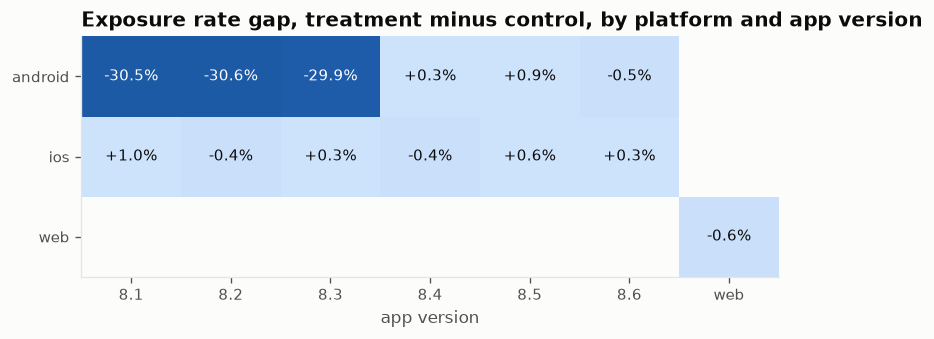

In [6]:
# Figure 1: treatment-minus-control exposure gap by platform and app version.
grid = (seg.table[seg.table["platform"] != "<all>"]
        .pivot(index="platform", columns="app_version", values="gap")
        .reindex(index=["android", "ios", "web"]))
grid = grid[[c for c in ["8.1", "8.2", "8.3", "8.4", "8.5", "8.6", "web"] if c in grid.columns]]
fig, ax = plt.subplots(figsize=(7.5, 2.6))
mat = np.ma.masked_invalid(-grid.to_numpy(dtype=float))  # loss magnitude, one hue light->dark
cmap = BLUE_CMAP.copy()
cmap.set_bad(PALETTE["surface"])  # cells that do not exist (web has no app version) stay blank
im = ax.imshow(mat, cmap=cmap, vmin=0, vmax=0.4, aspect="auto")
ax.set_xticks(range(grid.shape[1]), grid.columns)
ax.set_yticks(range(grid.shape[0]), grid.index)
ax.grid(False)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.iat[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:+.1%}" if abs(v) > 1e-9 else "0",
                    ha="center", va="center", fontsize=9,
                    color="white" if -v > 0.2 else PALETTE["ink"])
ax.set_title("Exposure rate gap, treatment minus control, by platform and app version")
ax.set_xlabel("app version")
fig.savefig(FIG / "fig1_exposure_gap_by_segment.png")
plt.show()

The loss is confined to Android on app versions below 8.4, on the treatment side only, at roughly a third of those users. Every other cell is at parity. The monitoring table the platform team publishes (`telemetry_health`, arms pooled) shows the same cells losing events, which is the clue an investigator would take to the client engineers: the redesigned widget's analytics emitter initialises after first paint on older Android builds and the render event is lost when the user navigates within the first second. The platform sees server-side renders only as these aggregate counts per platform, version and day; there is no user-level server render log to re-trigger the analysis on.

In [7]:
(telemetry.assign(old_android=lambda d: (d["platform"] == "android")
                  & version_below(d["app_version"].to_numpy(), "8.4"))
 .groupby(["platform", "old_android"])["event_loss_rate"].mean().round(4).rename("mean event loss rate"))

platform  old_android
android   False          0.0000
          True           0.1777
ios       False          0.0000
web       False          0.0000
Name: mean event loss rate, dtype: float64

## Step 4: invariants on the assigned and on the exposed population

Pre-treatment attributes that randomisation should have balanced: platform mix, app-version mix, country mix, and the 28-day pre-period order count. Run twice: on everyone assigned, and on the population the dashboard actually compares.

In [8]:
assigned_pop = assignments.merge(users, on="user_id")
exposed_pop = exposed_users.merge(users, on="user_id")
metrics = ["platform", "app_version", "country", "pre_period_orders_28d"]
inv_assigned = invariant_check(assigned_pop, arm_col="arm", metric_cols=metrics, level="assigned",
                               treatment_arm="treatment", control_arm="control")
inv_exposed = invariant_check(exposed_pop, arm_col="arm", metric_cols=metrics, level="exposed",
                              treatment_arm="treatment", control_arm="control")
cols = ["metric", "kind", "difference", "p_value", "flag"]
pd.concat({"assigned": inv_assigned.table[cols], "exposed": inv_exposed.table[cols]}).round(5)

metric         kind  difference  p_value   flag
assigned 0               platform  categorical     0.00293  0.26317  False
         1            app_version  categorical     0.00199  0.44095  False
         2                country  categorical     0.00214  0.76082  False
         3  pre_period_orders_28d      numeric    -0.00094  0.88283  False
exposed  0               platform  categorical     0.01850  0.00000   True
         1            app_version  categorical     0.01574  0.00000   True
         2                country  categorical     0.00290  0.44576  False
         3  pre_period_orders_28d      numeric     0.00756  0.27925  False

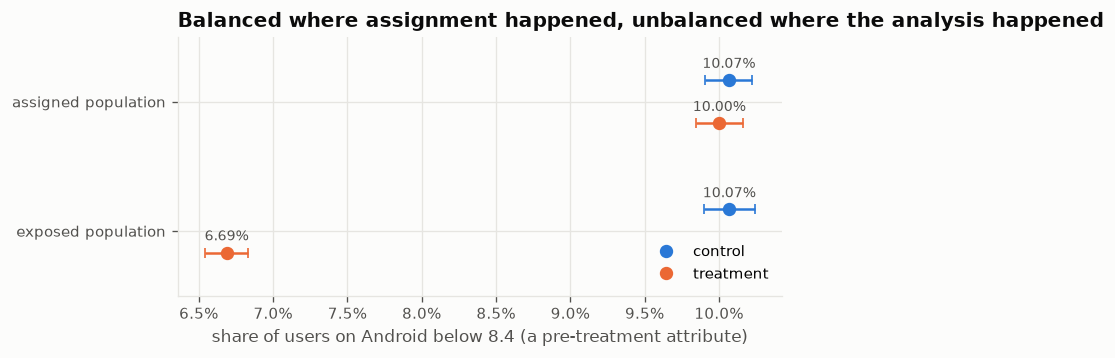

In [9]:
# Figure 2: the invariant that fails. Share of users in the affected cell (Android < 8.4)
# per arm, on the assigned and on the exposed population, with 95% intervals.
def share_ci(mask):
    p, n = mask.mean(), len(mask)
    return p, 1.96 * np.sqrt(p * (1 - p) / n)

rows = []
for pop_name, pop in [("assigned", assigned_pop), ("exposed", exposed_pop)]:
    cell = (pop["platform"] == "android") & version_below(pop["app_version"].to_numpy(), "8.4")
    for arm in ["control", "treatment"]:
        p, h = share_ci(cell[pop["arm"] == arm])
        rows.append((pop_name, arm, p, h))
pts = pd.DataFrame(rows, columns=["population", "arm", "share", "half"])
ypos = {("assigned", "control"): 3.0, ("assigned", "treatment"): 2.4,
        ("exposed", "control"): 1.2, ("exposed", "treatment"): 0.6}
fig, ax = plt.subplots(figsize=(6.5, 2.8))
for _, r in pts.iterrows():
    yy = ypos[(r["population"], r["arm"])]
    ax.errorbar(r["share"], yy, xerr=r["half"], fmt="o", color=PALETTE[r["arm"]], capsize=3, lw=1.5)
    ax.text(r["share"], yy + 0.17, f"{r['share']:.2%}", ha="center", fontsize=8.5, color=PALETTE["ink2"])
ax.set_yticks([2.7, 0.9], ["assigned population", "exposed population"])
ax.set_ylim(0, 3.6)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.1%}")
ax.set_xlabel("share of users on Android below 8.4 (a pre-treatment attribute)")
ax.set_title("Balanced where assignment happened, unbalanced where the analysis happened")
ax.legend(handles=[plt.Line2D([], [], marker="o", color=PALETTE[a], ls="", label=a)
                   for a in ["control", "treatment"]], loc="lower right")
fig.savefig(FIG / "fig2_affected_cell_share.png")
plt.show()

On the assigned population every invariant is balanced. On the exposed population the platform and app-version mix are flagged: the exposed treatment arm has fewer old-Android users than the exposed control arm, and that cell is the lowest-converting one, so any outcome comparison on this population is tilted in treatment's favour.

The pre-period order count moves in the expected direction but is **not** flagged, and the arithmetic below says why: the lost users are a small share of the exposed treatment arm and differ from it by a fraction of an order, so the expected shift in the arm mean is little more than one standard error of the difference, and a test at a 0.001 threshold has almost no power there. A composition invariant (which users are here) catches the removal because the removed users all sit in one category; an outcome-proxy invariant (what those users did before) fires only when the removed group is very different from the rest. Run both, and never read a pass on the second as a clean bill of health.

In [10]:
# Why the pre-period invariant does not fire: expected shift versus its standard error.
exp_t = exposed_pop[exposed_pop["arm"] == "treatment"]
t_users = assigned_pop[assigned_pop["arm"] == "treatment"]
t_cell = (t_users["platform"] == "android") & version_below(t_users["app_version"].to_numpy(), "8.4")
# Lost treatment users in excess of the arm-independent non-render share: estimated as the
# affected-cell users the exposed treatment arm is missing relative to control's exposure rate.
ctl_users = assigned_pop[assigned_pop["arm"] == "control"]
ctl_cell = (ctl_users["platform"] == "android") & version_below(ctl_users["app_version"].to_numpy(), "8.4")
ctl_rate_cell = ctl_users.loc[ctl_cell, "user_id"].isin(exposed_users["user_id"]).mean()
t_rate_cell = t_users.loc[t_cell, "user_id"].isin(exposed_users["user_id"]).mean()
excess_lost = (ctl_rate_cell - t_rate_cell) * t_cell.sum()
# Removing k users from an arm of n + k moves its mean by k / (n + k) x (full mean - removed mean).
share_lost = excess_lost / (len(exp_t) + excess_lost)  # share of rendered treatment users
cell_mean = t_users.loc[t_cell, "pre_period_orders_28d"].mean()
arm_mean = exp_t["pre_period_orders_28d"].mean()
shift = share_lost * (arm_mean - cell_mean)
sd = assigned_pop["pre_period_orders_28d"].std()
exp_c = exposed_pop[exposed_pop["arm"] == "control"]
se = sd * np.sqrt(1 / len(exp_t) + 1 / len(exp_c))
print(f"excess lost users: {excess_lost:,.0f} = {share_lost:.1%} of rendered treatment users "
      f"({excess_lost / len(t_users):.1%} of the treatment arm)")
realised_p = inv_exposed.table.set_index("metric").loc["pre_period_orders_28d", "p_value"]
print(f"realised pre-period test on the exposed population: p = {realised_p:.3f} (threshold 0.001)")
print(f"affected-cell mean pre-period orders {cell_mean:.2f} vs exposed treatment arm {arm_mean:.2f}")
print(f"expected shift in the arm mean {shift:.4f}; SE of the difference {se:.4f}; ratio {shift / se:.1f}")

excess lost users: 4,225 = 3.6% of rendered treatment users (3.0% of the treatment arm)
realised pre-period test on the exposed population: p = 0.279 (threshold 0.001)
affected-cell mean pre-period orders 0.36 vs exposed treatment arm 0.59
expected shift in the arm mean 0.0082; SE of the difference 0.0070; ratio 1.2


## Step 5: outcome-event completeness

Orders reach the warehouse with a 0 to 36 hour delay. Two questions: is the delay the same in both arms, and how much of the outcome is missing at the moment the dashboard was rendered?

In [11]:
lag_dashboard = event_arrival_lag(orders, assignments, event_time_col="ordered_at",
                                  received_time_col="received_at", analysis_time=dashboard_time)
lag_final = event_arrival_lag(orders, assignments, event_time_col="ordered_at",
                              received_time_col="received_at", analysis_time=analysis_time)
print(f"KS test between arms: D={lag_dashboard.ks_statistic:.4f}, p={lag_dashboard.ks_p_value:.3f}, "
      f"differential={lag_dashboard.differential}")
open_window = (assignments["assigned_at"] + window > dashboard_time).groupby(assignments["arm"]).mean()
print("share of users whose 7-day window had not closed at dashboard time:",
      open_window.round(3).to_dict())
placed = orders[orders["ordered_at"] <= dashboard_time]
print(f"orders placed by dashboard time but not yet received: {(placed['received_at'] > dashboard_time).mean():.1%} "
      f"of {len(placed):,}")
pd.concat({"at dashboard time": lag_dashboard.table.set_index("arm"),
           "at analysis time": lag_final.table.set_index("arm")}).round(3)

KS test between arms: D=0.0217, p=0.236, differential=False
share of users whose 7-day window had not closed at dashboard time: {'control': 0.499, 'treatment': 0.501}
orders placed by dashboard time but not yet received: 5.1% of 8,548


n_events  mean_lag_h  median_lag_h  p90_lag_h  \
                  arm                                                        
at dashboard time control        4458      18.100        18.221     32.530   
                  treatment      4532      17.821        17.581     32.211   
at analysis time  control        4458      18.100        18.221     32.530   
                  treatment      4532      17.821        17.581     32.211   

                             max_lag_h  share_unavailable_at_analysis  
                  arm                                                  
at dashboard time control       36.000                          0.101  
                  treatment     35.998                          0.095  
at analysis time  control       36.000                          0.000  
                  treatment     35.998                          0.000

The delay is identical across arms (non-differential) and it creates no SRM, so a sample-ratio check would never see it. At dashboard time about one order in twenty already placed had not arrived (the table's `share_unavailable_at_analysis` column divides by every eventual order, including those placed later, and so reads higher), and half of all users had not finished their 7-day outcome window. Neither problem biases the comparison between arms, because both hit the arms equally; both bias the *level* of the metric downward and shrink the effective sample. The correct handling is to wait for `analysis_time`, or to restrict to cohorts whose window has closed. This notebook uses `analysis_time`.

## Step 6: the estimate, on each population

Outcome: at least one order within 7 days of assignment. Four numbers: what the dashboard showed on day 14 (exposed users, orders received by `dashboard_time`); the same exposed-population comparison on complete data (orders received by `analysis_time`); the exposed comparison with the affected segment (Android below 8.4) removed from both arms, a pre-treatment exclusion that leaves a population whose logging is intact; and the pre-registered intent-to-treat estimate on the assigned population at `analysis_time`.

In [12]:
o_all = orders.merge(assignments[["user_id", "assigned_at"]], on="user_id")
o = o_all[(o_all["ordered_at"] >= o_all["assigned_at"])
          & (o_all["ordered_at"] < o_all["assigned_at"] + window)
          & (o_all["received_at"] <= analysis_time)]
converters = set(o["user_id"])

def counts(pop):
    out = {}
    for arm in ["treatment", "control"]:
        ids = pop.loc[pop["arm"] == arm, "user_id"]
        out[arm] = (int(ids.isin(converters).sum()), int(len(ids)))
    return out

c_assigned, c_exposed = counts(assignments), counts(exposed_users)
ctl = assigned_pop[assigned_pop["arm"] == "control"].assign(converted=lambda d: d["user_id"].isin(converters))
ctl_cell = (ctl["platform"] == "android") & version_below(ctl["app_version"].to_numpy(), "8.4")
print(f"control-arm conversion, affected cell {ctl.loc[ctl_cell, 'converted'].mean():.4%} "
      f"vs rest {ctl.loc[~ctl_cell, 'converted'].mean():.4%} "
      f"(ratio {ctl.loc[ctl_cell, 'converted'].mean() / ctl.loc[~ctl_cell, 'converted'].mean():.2f})")
itt = difference_in_proportions(*c_assigned["treatment"], *c_assigned["control"],
    estimand="ITT difference in 7-day order rate among eligible users", analysis_unit="user", population="assigned")
naive = difference_in_proportions(*c_exposed["treatment"], *c_exposed["control"],
    estimand="difference in 7-day order rate among exposed users", analysis_unit="user", population="exposed")
o_dash = o_all[(o_all["ordered_at"] >= o_all["assigned_at"])
              & (o_all["ordered_at"] < o_all["assigned_at"] + window)
              & (o_all["received_at"] <= dashboard_time)]
converters_dash = set(o_dash["user_id"])
c_dash = {arm: (int(ids.isin(converters_dash).sum()), int(len(ids)))
          for arm, ids in ((a, exposed_users.loc[exposed_users["arm"] == a, "user_id"])
                           for a in ["treatment", "control"])}
dashboard = difference_in_proportions(*c_dash["treatment"], *c_dash["control"],
    estimand="difference in order rate among exposed users, as received by day 14",
    analysis_unit="user", population="exposed")
outside = exposed_users.merge(users[["user_id", "platform", "app_version"]], on="user_id")
outside = outside[~((outside["platform"] == "android")
                    & version_below(outside["app_version"].to_numpy(), "8.4"))]
excl = difference_in_proportions(*counts(outside)["treatment"], *counts(outside)["control"],
    estimand="difference in order rate among exposed users outside the affected segment",
    analysis_unit="user", population="exposed, affected segment excluded")
print("dashboard, day 14        :", dashboard.summary())
print("exposed, complete data   :", naive.summary())
print("exposed, segment removed :", excl.summary())
print("ITT, complete data       :", itt.summary())

control-arm conversion, affected cell 1.7362% vs rest 3.3422% (ratio 0.52)


dashboard, day 14        : exposed population, user level: treatment 3.0356% vs control 2.8528%; difference +0.1828% [+0.0457%, +0.3199%], relative +6.41% [+1.57%, +11.48%], p=0.00892.
exposed, complete data   : exposed population, user level: treatment 3.3416% vs control 3.1666%; difference +0.1750% [+0.0311%, +0.3188%], relative +5.53% [+0.96%, +10.30%], p=0.0171.
exposed, segment removed : exposed, affected segment excluded population, user level: treatment 3.4531% vs control 3.3252%; difference +0.1278% [-0.0254%, +0.2811%], relative +3.84% [-0.75%, +8.65%], p=0.102.
ITT, complete data       : assigned population, user level: treatment 3.2409% vs control 3.1806%; difference +0.0604% [-0.0702%, +0.1910%], relative +1.90% [-2.16%, +6.13%], p=0.365.


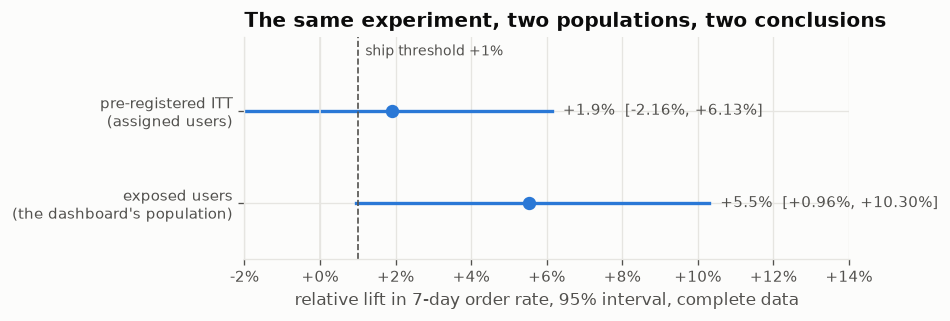

In [13]:
# Figure 3: relative lift with 95% interval on the two populations, against the ship threshold.
fig, ax = plt.subplots(figsize=(6.5, 2.4))
# Both rows are the same contrast (treatment vs control) on different populations, so they
# share one colour; the row label carries identity.
for yy, r in enumerate([naive, itt]):  # both on complete data, at analysis_time
    lo, hi = r.relative_confidence_interval
    ax.plot([lo, hi], [yy, yy], color=PALETTE["control"], lw=2)
    ax.plot(r.relative_lift, yy, "o", color=PALETTE["control"])
    ax.text(hi + 0.003, yy, f"{r.relative_lift:+.1%}  [{lo:+.2%}, {hi:+.2%}]", va="center", fontsize=9, color=PALETTE["ink2"])
ax.axvline(threshold, color=PALETTE["threshold"], ls="--", lw=1)
ax.text(threshold + 0.002, 1.6, f"ship threshold {threshold:+.0%}", fontsize=8.5, color=PALETTE["ink2"], ha="left")
ax.axvline(0, color=PALETTE["grid"], lw=1)
ax.set_yticks([0, 1], ["exposed users\n(the dashboard's population)", "pre-registered ITT\n(assigned users)"])
ax.set_xlim(-0.02, 0.14)
ax.set_ylim(-0.6, 1.8)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:+.0%}")
ax.set_xlabel("relative lift in 7-day order rate, 95% interval, complete data")
ax.set_title("The same experiment, two populations, two conclusions")
fig.savefig(FIG / "fig3_naive_vs_itt.png")
plt.show()

## Step 7: guardrails and decision

Each guardrail has a pre-declared non-inferiority margin in `config.yaml` (a product input, like the ship threshold), applied to the treatment-minus-control difference: it passes when the upper 95% bound is at or below the margin, breaches when the lower 95% bound is above it, and is inconclusive otherwise.

The latency guardrail is measured by the widget's own timing event. Where the render event was lost, so was the latency measurement, and fallback users never have one. The estimator is the ratio of treatment to control p95 latency over each arm's measured loads, with a 95% interval from a bootstrap that resamples users (a user contributes about 1.3 loads, so loads are clustered). It is computed overall and within the affected segment. In this simulation the loss is random within the affected cell, so the measured affected loads are a random sample and the segment estimate is unbiased here. In a real incident the mechanism described (users navigating away within the first second) ties the loss to behaviour, and the measured loads could then misrepresent the segment; that unverified mechanism is what keeps the latency guardrail a blocker for the affected segment.

In [14]:
lat = attempts.merge(assignments[["user_id", "arm"]], on="user_id").merge(users[["user_id", "platform", "app_version"]], on="user_id")
lat["old_android"] = (lat["platform"] == "android") & version_below(lat["app_version"].to_numpy(), "8.4")
cov = lat.groupby(["arm", "old_android"])["latency_ms"].agg(loads="size", measured=lambda s: s.notna().mean(), p95=lambda s: s.quantile(0.95))
print(cov.round(3))
margins = config["decision_rule"]["guardrails"]
p95 = lat.dropna(subset=["latency_ms"]).groupby("arm")["latency_ms"].quantile(0.95)
print(f"p95 latency on measured loads: treatment {p95['treatment']:.0f} ms, control "
      f"{p95['control']:.0f} ms ({p95['treatment'] / p95['control'] - 1:+.1%})")


# Defined here, outside the package: user-clustered bootstrap of the p95 ratio.
def p95_ratio_interval(frame, n_boot=2000, seed=20260928):
    # User-clustered bootstrap of the treatment/control p95 ratio on measured loads.
    rng = np.random.default_rng(seed)
    m = frame.dropna(subset=["latency_ms"])
    per_arm = {}
    for arm in ("treatment", "control"):
        g = m[m["arm"] == arm]
        codes, uniq = pd.factorize(g["user_id"])
        order = np.argsort(codes, kind="stable")
        values = g["latency_ms"].to_numpy()[order]
        starts = np.searchsorted(codes[order], np.arange(len(uniq)))
        per_arm[arm] = (values, starts, np.diff(np.append(starts, len(values))))
    ratios = []
    for _ in range(n_boot):
        q = {}
        for arm, (values, starts, sizes) in per_arm.items():
            pick = rng.integers(0, len(starts), len(starts))
            k = sizes[pick]
            idx = np.repeat(starts[pick] - np.cumsum(np.r_[0, k[:-1]]), k) + np.arange(k.sum())
            q[arm] = np.quantile(values[idx], 0.95)
        ratios.append(q["treatment"] / q["control"] - 1)
    point = m[m.arm == "treatment"]["latency_ms"].quantile(0.95) / m[m.arm == "control"]["latency_ms"].quantile(0.95) - 1
    return point, np.quantile(ratios, 0.025), np.quantile(ratios, 0.975)


# Defined here, outside the package: the pre-declared verdict rule.
def guardrail_verdict(upper, lower, margin):
    if upper <= margin:
        return "pass"
    return "breach" if lower > margin else "inconclusive"


m_lat = margins["latency_p95_max_increase_relative"]
for label, frame in (("all segments", lat), ("affected segment", lat[lat["old_android"]])):
    point, lo, hi = p95_ratio_interval(frame)
    print(f"p95 ratio, {label}: {point:+.1%} [{lo:+.1%}, {hi:+.1%}] against margin +{m_lat:.0%}: "
          f"{guardrail_verdict(hi, lo, m_lat)} (measured share of affected treatment loads "
          f"{lat.loc[lat['old_android'] & (lat['arm'] == 'treatment'), 'latency_ms'].notna().mean():.1%})")
measured = lat.dropna(subset=["latency_ms"])
print("affected-segment share of measured loads by arm:",
      measured.groupby("arm")["old_android"].mean().round(4).to_dict(),
      "(the overall ratio mixes segments in different proportions by arm; the segments' p95s are",
      "within about 1% of each other here, so the mix does not move it)")

                        loads  measured      p95
arm       old_android                           
control   False        163779     0.851  2134.20
          True          18360     0.852  2117.00
treatment False        163785     0.851  2139.80
          True          18107     0.547  2118.08
p95 latency on measured loads: treatment 2138 ms, control 2133 ms (+0.3%)


p95 ratio, all segments: +0.3% [-0.2%, +0.8%] against margin +5%: pass (measured share of affected treatment loads 54.7%)


p95 ratio, affected segment: +0.1% [-1.6%, +1.8%] against margin +5%: pass (measured share of affected treatment loads 54.7%)
affected-segment share of measured loads by arm: {'control': 0.101, 'treatment': 0.0663} (the overall ratio mixes segments in different proportions by arm; the segments' p95s are within about 1% of each other here, so the mix does not move it)


The payment-step guardrail is measured at the user level, the unit of randomisation: the share of assigned users with at least one payment-step load that raised a client error, through the widget or the fallback. A load is a visit to the payment step, not a payment, so most loads end without an order. The denominator is every assigned user, so no post-assignment filter enters it. (The per-load error rate is a ratio metric whose variance needs the delta method; that is Case 02's subject.) Loads per user are reported by arm, because a redesign that changes how often users reload the step would move "any error" mechanically.

In [15]:
per_user = attempts.groupby("user_id").agg(any_error=("payment_step_error", "any"),
                                           n_loads=("payment_step_error", "size"))
pf = assignments[["user_id", "arm"]].merge(per_user, on="user_id", how="left")
pf["any_error"] = pf["any_error"].fillna(False).astype(bool)
pf["n_loads"] = pf["n_loads"].fillna(0)
print("payment-step loads per assigned user by arm:", pf.groupby("arm")["n_loads"].mean().round(4).to_dict())
pf_counts = {arm: (int(g["any_error"].sum()), int(len(g))) for arm, g in pf.groupby("arm")}
payment = difference_in_proportions(*pf_counts["treatment"], *pf_counts["control"],
    estimand="difference in share of assigned users with a payment-step error", analysis_unit="user",
    population="assigned")
print(payment.summary())
m = margins["payment_step_error_max_increase_absolute"]
print(f"margin +{m * 100:.1f} points absolute: {guardrail_verdict(payment.confidence_interval[1], payment.confidence_interval[0], m)}")

payment-step loads per assigned user by arm: {'control': 1.2995, 'treatment': 1.3008}
assigned population, user level: treatment 5.1246% vs control 5.1568%; difference -0.0322% [-0.1958%, +0.1313%], relative -0.63% [-3.74%, +2.59%], p=0.699.
margin +0.3 points absolute: pass


The refund guardrail has a clock of its own. A refund can arrive up to 14 days after the order, so at `analysis_time` the refund window is still open for every order placed in the previous 14 days. Counting the refunds seen so far over all orders understates the rate, and a treatment that shifts refunds later would look better than it is. The guardrail is therefore computed only on orders whose 14-day window has closed by `analysis_time`. It is breach-only: a breach of its +10% margin stops the launch, and a pass is not required, because at this cohort size a +10% margin passes a harmless change only about 18% of the time. Two dates matter: the design date, fixed before the experiment (the last possible order from the interim cohorts, at the end of the last such user's outcome window, plus 14 days), and the date this run's last actual order matures. The matured cohort consists of early orders, from users who enrolled in about the first 8.4 days, so it says nothing yet about the later enrolees. The slowest guardrail sets the earliest date on which a complete decision can be taken. (With one order per converter in v1, order and user coincide. Conditioning on having ordered is a post-treatment selection; it is harmless here only because the simulated effect on refunds is zero, and the README flags it.)

In [16]:
refund_window = pd.Timedelta(days=14)
ro = orders.merge(assignments[["user_id", "arm"]], on="user_id")
ro = ro[ro["received_at"] <= analysis_time]
matured = ro["ordered_at"] + refund_window <= analysis_time
seen = ro["refunded_at"].notna() & (ro["refunded_at"] <= analysis_time)
design_date = dashboard_time + window + refund_window
fully_measured = ro["ordered_at"].max() + refund_window
enrolled = ro.loc[matured, "user_id"].map(assignments.set_index("user_id")["assigned_at"])
print(f"orders visible at analysis_time: {len(ro):,}; refund window closed for {matured.mean():.1%}")
print(f"refund guardrail complete by design for the interim cohorts on {design_date:%Y-%m-%d} "
      f"({(design_date - analysis_time) / pd.Timedelta(days=1):.1f} days after data-complete); this run's last "
      f"order matures on {fully_measured:%Y-%m-%d %H:%M}")
print(f"matured orders come from users enrolled up to {enrolled.max():%Y-%m-%d %H:%M}")
naive_rate = seen.mean()
mat = ro[matured].assign(refunded=seen[matured])
r_counts = {arm: (int(g["refunded"].sum()), int(len(g))) for arm, g in mat.groupby("arm")}
refund = difference_in_proportions(*r_counts["treatment"], *r_counts["control"],
    estimand="difference in 14-day refund rate per order", analysis_unit="order (one per converter)",
    population="orders whose refund window closed by analysis_time")
print(f"refund rate counting open windows (understated): {naive_rate:.2%}; matured cohort: "
      f"treatment {refund.rate_treatment:.2%}, control {refund.rate_control:.2%}")
print(refund.summary())
m = margins["refund_rate_max_increase_relative"]
lo, hi = refund.relative_confidence_interval
verdict = guardrail_verdict(hi, lo, m)
print(f"margin +{m:.0%} relative (breach-only): {verdict}; "
      f"{'breach' if verdict == 'breach' else 'no breach on the matured cohort so far'}")

orders visible at analysis_time: 8,990; refund window closed for 54.8%
refund guardrail complete by design for the interim cohorts on 2026-04-06 (12.5 days after data-complete); this run's last order matures on 2026-04-04 11:31
matured orders come from users enrolled up to 2026-03-10 10:26
refund rate counting open windows (understated): 4.63%; matured cohort: treatment 5.04%, control 4.98%
orders whose refund window closed by analysis_time population, order (one per converter) level: treatment 5.0444% vs control 4.9755%; difference +0.0689% [-1.1490%, +1.2868%], relative +1.38% [-20.50%, +29.29%], p=0.912.
margin +10% relative (breach-only): inconclusive; no breach on the matured cohort so far


### Decision blockers

| Blocker | Status |
|---|---|
| Assignment issue | none: assignment-level counts and invariants pass |
| Exposure measurement issue | **open**: treatment-side render event lost for Android < 8.4 |
| Outcome logging issue | non-differential batch delay; handled by using `analysis_time` |
| Differential missingness | **open**, on exposure only |
| Guardrail unmeasurable or not yet mature | **open**: latency missing for about 45% of affected treatment loads (15% elsewhere) under an unverified loss mechanism; refund guardrail read on the matured cohort only until its window closes |
| Duration insufficient for delayed outcomes | none once `analysis_time` is used |

### Recommendation

Analysing triggered (exposed) users is standard practice and valid when the trigger fires independently of arm; it is what gives triggered analyses their sensitivity. Here the trigger event itself is lost differentially, so the exposed population is no longer a random subset of the assigned one and the dashboard's estimate is biased upward: the users it lost were the lowest-converting treatment users. The intent-to-treat estimate is valid, and on its own its interval falls in the rule's continue zone; under the ordered rule the open blockers come first, so the rule gives no decision until they are resolved. Removing the affected segment from both arms gives a valid exposed-population estimate for rendered users outside that segment (about 76% of eligible users); its lift is on the triggered scale, so the +1.0% ITT floor does not apply to it directly, and it describes a different population from the one the decision is about. The blockers stand regardless of the estimates: the exposure pipeline, the latency guardrail and the refund guardrail's maturity. Recommendation: do not ship; stop the experiment, whose remaining enrolment carries the same defect; fix the emitter on Android < 8.4; run an A/A on the exposure pipeline to confirm parity; rerun the experiment under the same pre-declared design with the fix in place. Full memo: `decision_memo.md`.

### What this case establishes

The standard sample-ratio check passed, and the failure lived one level down, in the population the analysis was run on. Validity belongs to the comparison, and the first question in any review is whether the analysed population is the randomised one.